
# Week 7: Hands-On ML Solution Data Visualizations

## Dataset 1: Customer Demographics

### 1. Introduction

This notebook explores the Customer Demographics dataset prepared during Milestone 1. The main purpose is to understand the information about customers through statistical calculations and visual representations using Python.

The analysis will focus on customer ages and gender distribution. By examining these characteristics, I aim to identify patterns in the data and gather useful observations that may support future machine learning activities.


In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the default visualization style
sns.set_theme(style="whitegrid")

print("All libraries are ready to use.")

All libraries are ready to use.



### 2. Loading the Cleaned Dataset

The cleaned Customer Demographics CSV file will be loaded into a Pandas DataFrame. Using the preprocessed file allows me to continue the analysis from Milestone 1 without repeating the original cleaning process.


In [2]:
# Load the cleaned Customer Demographics dataset
demographics = pd.read_csv(
    "customer_demographics_preprocessed.csv"
)

print("Customer Demographics dataset loaded successfully.")

Customer Demographics dataset loaded successfully.



### 3. Initial Dataset Inspection

Before calculating statistics, I will check the dataset's structure and contents. This includes reviewing sample records, column names, data types, missing values, and duplicate rows to confirm that the file is ready for analysis.


In [3]:
# Display the first five records
display(demographics.head())

# Check dataset dimensions
print("Dataset shape:", demographics.shape)

# Display column names
print("\nColumn names:")
print(demographics.columns.tolist())

# Check data types
print("\nData types:")
print(demographics.dtypes)

# Check missing values
print("\nMissing values:")
print(demographics.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:",
      demographics.duplicated().sum())

,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
0,0009fdd2-ae63-45ca-8d5b-d0ea98381f7b,21.0,Female,Lake George,Low,2020-11-09
1,000c6bbd-533a-432d-922c-ab64197e71c5,25.0,Male,North Oliviaton,High,2019-11-06
2,00115fc0-f155-42cd-ba68-58aab67b3360,36.0,Male,Nelsonstad,Low,2022-02-16
3,00145374-004a-4685-af4d-c8a8967b969e,69.0,Female,Jacquelinehaven,Unknown,2023-04-28
4,0047d8ce-a5bb-4db7-860f-6ff66e1cd060,40.0,Male,Mitchellview,Medium,2021-11-11


Dataset shape: (3000, 6)

Column names:
['CustomerID', 'Age', 'Gender', 'Location', 'IncomeLevel', 'SignupDate']

Data types:
CustomerID         str
Age            float64
Gender             str
Location           str
IncomeLevel        str
SignupDate         str
dtype: object

Missing values:
CustomerID     0
Age            0
Gender         0
Location       0
IncomeLevel    0
SignupDate     0
dtype: int64

Number of duplicate rows: 0



### 4. Descriptive Statistics Using NumPy

In this section, I will examine the ages recorded in the dataset using NumPy. The calculations will include the mean, median, standard deviation, variance, minimum, maximum, range, and quartiles. These measures will help describe the typical customer age and show how widely the ages vary.


In [5]:
# Convert Age into numeric values and exclude invalid entries
age = pd.to_numeric(
    demographics["Age"],
    errors="coerce"
).dropna().to_numpy()

# Calculate statistical measures
age_statistics = {
    "Valid Age Count": len(age),
    "Mean": np.mean(age),
    "Median": np.median(age),
    "Standard Deviation": np.std(age, ddof=1),
    "Variance": np.var(age, ddof=1),
    "Minimum": np.min(age),
    "Maximum": np.max(age),
    "Range": np.ptp(age),
    "25th Percentile": np.percentile(age, 25),
    "75th Percentile": np.percentile(age, 75)
}

# Display the results
for statistic, value in age_statistics.items():
    if statistic == "Valid Age Count":
        print(f"{statistic}: {value}")
    else:
        print(f"{statistic}: {value:.2f}")

Valid Age Count: 3000
Mean: 44.66
Median: 45.00
Standard Deviation: 14.45
Variance: 208.88
Minimum: 18.00
Maximum: 70.00
Range: 52.00
25th Percentile: 33.75
75th Percentile: 57.00



### 5. Visualization 1: Customer Age Distribution

A histogram will show how customer ages are grouped across different ranges. This chart will help me identify where ages are concentrated, how the values are spread, and whether the distribution appears balanced or skewed. Any unusual values can also be examined more closely.


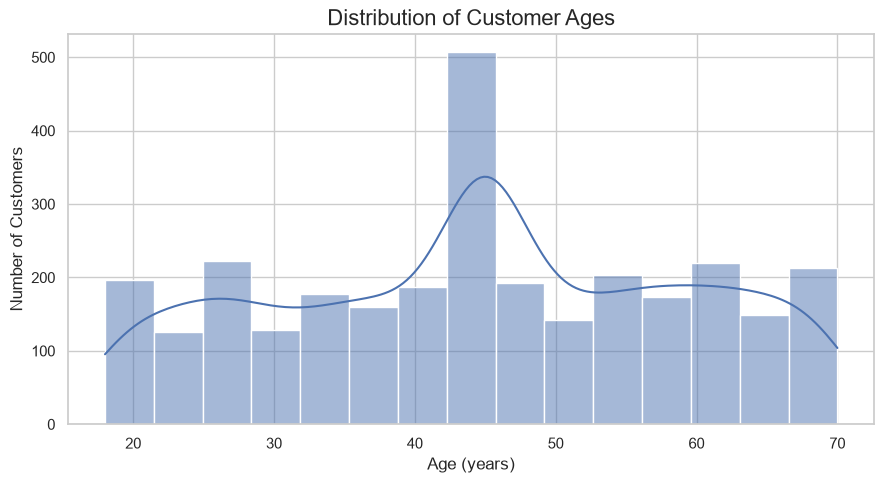

In [6]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=demographics,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Distribution of Customer Ages", fontsize=16)
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.tight_layout()
plt.show()


### 6. Interpretation of Customer Age Distribution

The histogram shows that customer ages range from approximately 18 to 70 years. The largest concentration appears around the mid-40s, with the age group near 44–46 having the highest frequency. Other age ranges have relatively moderate numbers of customers, although there are some differences in frequency across the chart.

The distribution is not completely uniform because certain age ranges occur more frequently than others. This suggests that some age groups are more represented in the dataset. These patterns can help us understand the demographic composition of the customers and may be useful when exploring customer groups for future machine learning analysis.



### 7. Visualization 2: Customer Gender Distribution

This visualization compares the number of customers in each gender category. A bar chart makes the differences between categories easier to see and helps identify whether one group is more represented than the others.


Customer counts by gender:
Gender
Female    1515
Male      1485
Name: count, dtype: int64


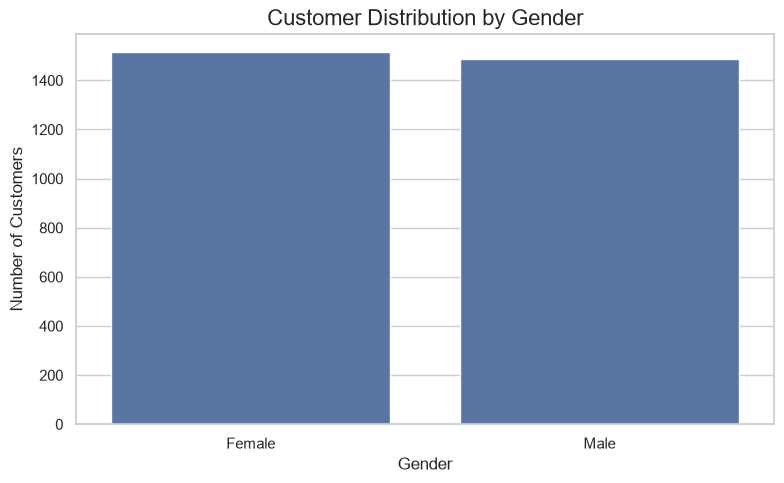

In [8]:
# Count customers in each gender category
gender_counts = demographics["Gender"].value_counts(
    dropna=False
)

print("Customer counts by gender:")
print(gender_counts)

# Create the bar chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=demographics,
    x="Gender",
    order=demographics["Gender"].value_counts().index
)

plt.title("Customer Distribution by Gender", fontsize=16)
plt.xlabel("Gender", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 8. Interpretation of Customer Gender Distribution

The results show that the dataset contains 1,515 female customers and 1,485 male customers. Female customers make up approximately 50.5% of the records, while male customers account for 49.5%. The difference between the two groups is only 30 customers, indicating that the gender distribution is nearly balanced. This means that neither category strongly dominates the dataset, which provides a fairly even representation of both groups for further demographic analysis.




### 9. Visualization 3: Customer Age Spread and Potential Outliers

A box plot provides another way to examine customer ages by showing the median, the middle 50% of the values, and the overall spread. It can also highlight ages that fall unusually far from the rest of the data. This complements the histogram by providing a more focused view of age variability.


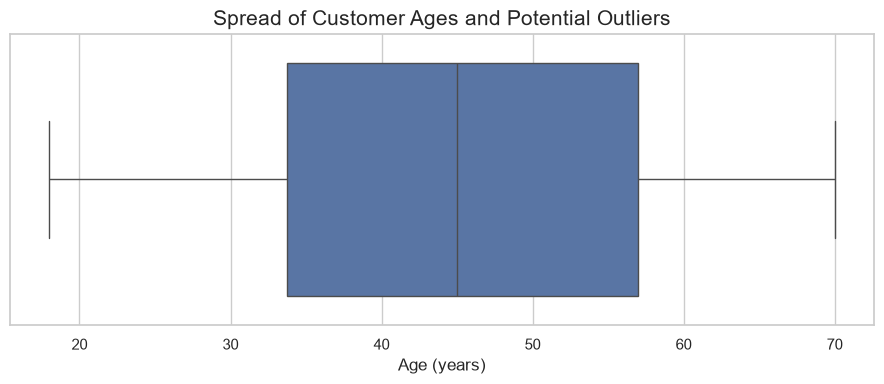

In [9]:
# Create a box plot of customer ages
plt.figure(figsize=(9, 4))

sns.boxplot(
    data=demographics,
    x="Age"
)

plt.title("Spread of Customer Ages and Potential Outliers", fontsize=15)
plt.xlabel("Age (years)", fontsize=12)
plt.tight_layout()
plt.show()


### 10. Interpretation of Customer Age Box Plot

The box plot shows that customer ages range from approximately 18 to 70 years. The median age is around 45 years, meaning that half of the customers are younger than or equal to this age and the other half are older than or equal to it. The middle 50% of customer ages fall roughly between 34 and 57 years, showing a fairly wide spread in the dataset. No individual points appear beyond the whiskers, so the chart does not identify any potential outliers based on the box plot's default criteria. Overall, the dataset represents customers from a broad range of adult age groups.



### 11. Summary of Customer Demographics

The analysis of customer demographics shows that the dataset contains a wide range of customer ages, with the highest concentration appearing around the mid-40s. The gender distribution is also nearly balanced, with 1,515 female customers and 1,485 male customers. The box plot does not display any potential outliers under its default detection rule. These findings provide an initial understanding of the customers represented in the dataset and can guide further analysis of customer behavior.
